# 06 · Crop-rotation planning with historical weather scenarios

**Task:** combine the historical weather record with crop water requirements to compare
rotation options for each region — the same shape as the AgriFusion engine, but driven
from the model-ready panel.

**The method is FAO-56 water balance, not machine learning.** For each candidate crop and
season:

1. `ETc = Kc × ET₀` — crop water use from the reference demand and the crop coefficient.
2. Effective rainfall from USDA-SCS: `Pe = (P − 0.2S)² / (P + 0.8S)`, `S = 25400/CN − 254`.
3. `Irrigation demand = max(0, ETc − Pe)`, accumulated over the season.
4. Heat exposure = days with `Tmax ≥ 35 °C` (the threshold used in the AgriFusion rule
   engine for rice/wheat heat stress).

The comparison is run over the **last four seasons of real weather**, so each option is
scored on the same years rather than on a long-run average that never occurred.

**What this is not:** it does not predict yield, price or profit; it says nothing about
markets; and the crop parameters are textbook values that must be replaced by the
project's reviewed catalogue before farmer-facing use.

In [1]:
# --- shared setup -----------------------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA = Path(os.environ.get("BH6_DATA", r"C:\Users\muhai\Desktop\BIG hero 6\Data"))
MR = DATA / "model_ready"
OUT = Path(os.environ.get("BH6_OUT", str(Path.cwd() / "outputs")))
OUT.mkdir(parents=True, exist_ok=True)

regions = ["Northwest_Rajshahi", "North_Rangpur", "Central_Dhaka", "Northeast_Sylhet",
           "Southwest_Khulna", "South_Barishal", "Southeast_Chattogram"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
SEQ = LinearSegmentedColormap.from_list("brand_blue", ["#eaf2fc", "#9cc3ef", "#2a78d6", "#12365f"])

def pretty(region):
    return region.replace("_", " ")

def load_daily():
    df = pd.read_csv(MR / "daily_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def load_monthly():
    df = pd.read_csv(MR / "monthly_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def split_by_date(dates, train_end="2024-12-31", valid_end="2025-12-31"):
    d = pd.to_datetime(dates)
    return (d <= train_end), (d > train_end) & (d <= valid_end), d > valid_end

def metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    if ok.sum() < 5:
        return {"n": int(ok.sum())}
    return {"n": int(ok.sum()),
            "MAE": round(float(mean_absolute_error(y_true[ok], y_pred[ok])), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y_true[ok], y_pred[ok]))), 3),
            "R2": round(float(r2_score(y_true[ok], y_pred[ok])), 3)}

print(f"pandas {pd.__version__} | data: {DATA}")


pandas 3.1.1 | data: C:\Users\muhai\Desktop\BIG hero 6\Data


## 1. Crop parameters

Kc values are FAO-56 Table 11 mid-season coefficients for the rainfed/irrigated
conditions typical of Bangladesh; season windows follow the BARC/DAE calendar
(boro = winter irrigated rice, aman = monsoon rice, aus = pre-monsoon rice).

**Replace these with the reviewed `catalogue.Crop` rows** before production use.

In [2]:
CROPS = [
    # name, season window (months), Kc mid, water demand class, notes
    {"crop": "Boro rice (paddy)", "months": [12, 1, 2, 3, 4], "kc": 1.20, "paddy": True},
    {"crop": "Aman rice (paddy)", "months": [6, 7, 8, 9, 10], "kc": 1.10, "paddy": True},
    {"crop": "Aus rice", "months": [4, 5, 6, 7], "kc": 1.10, "paddy": True},
    {"crop": "Wheat", "months": [11, 12, 1, 2, 3], "kc": 1.15, "paddy": False},
    {"crop": "Maize", "months": [11, 12, 1, 2, 3], "kc": 1.20, "paddy": False},
    {"crop": "Potato", "months": [11, 12, 1, 2], "kc": 1.15, "paddy": False},
    {"crop": "Mustard", "months": [10, 11, 12, 1], "kc": 1.10, "paddy": False},
    {"crop": "Lentil", "months": [11, 12, 1, 2], "kc": 1.10, "paddy": False},
    {"crop": "Jute", "months": [4, 5, 6, 7], "kc": 1.10, "paddy": False},
]
crop_df = pd.DataFrame(CROPS)
print(f"{len(crop_df)} candidate crops defined")
crop_df[["crop", "kc", "paddy"]]

9 candidate crops defined


,crop,kc,paddy
0,Boro rice (paddy),1.20,True
1,Aman rice (paddy),1.10,True
2,Aus rice,1.10,True
3,Wheat,1.15,False
4,Maize,1.20,False
5,Potato,1.15,False
6,Mustard,1.10,False
7,Lentil,1.10,False
8,Jute,1.10,False


## 2. Run the water balance over real seasons

For every region, crop and year we accumulate ETc, effective rainfall and the resulting
irrigation demand. Years where the season is not fully covered by the record are
dropped rather than partly counted.

In [3]:
CN = 70  # USDA-SCS curve number: mixed upland crops / vegetative cover
S_RETENTION = 25400 / CN - 254   # mm

def effective_rainfall(p_mm):
    """USDA-SCS effective rainfall, mm."""
    return np.where(p_mm > 0.2 * S_RETENTION,
                    (p_mm - 0.2 * S_RETENTION) ** 2 / (p_mm + 0.8 * S_RETENTION),
                    0.0)

daily = load_daily()
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month

records = []
for region in regions:
    g = daily[daily.region == region].set_index("date")
    for crop in CROPS:
        for year in range(2022, 2027):
            # a season that wraps the new year spans year-1 too
            months = crop["months"]
            parts = []
            for m in months:
                yr = year - 1 if (months[0] == 12 and m == 12) else year
                parts.append(g[(g.index.year == yr) & (g.index.month == m)])
            frame = pd.concat(parts) if parts else g.iloc[0:0]
            if len(frame) < 0.8 * len(months) * 28:
                continue
            et0 = frame["et0_best_mm"].sum()
            rain = frame["gpm_rain_mm"].sum()
            if not np.isfinite(et0) or not np.isfinite(rain) or et0 <= 0:
                continue
            etc = crop["kc"] * et0
            pe = float(effective_rainfall(np.array([rain]))[0])
            records.append({
                "region": region, "crop": crop["crop"], "year": year,
                "days": len(frame),
                "et0_mm": round(et0, 0),
                "etc_mm": round(float(etc), 0),
                "rain_mm": round(float(rain), 0),
                "effective_rain_mm": round(pe, 0),
                "irrigation_demand_mm": round(float(max(0, etc - pe)), 0),
                "heat_days_35": int((frame["tmax_c"] >= 35).sum()),
                "paddy": crop["paddy"],
            })

balance = pd.DataFrame(records)
balance.to_csv(OUT / "rotation_water_balance.csv", index=False)
print(f"{len(balance)} region-crop-year combinations scored")
balance.head()

280 region-crop-year combinations scored


,region,crop,year,days,et0_mm,etc_mm,rain_mm,effective_rain_mm,irrigation_demand_mm,heat_days_35,paddy
0,Northwest_Rajshahi,Boro rice (paddy),2022,120,485.0,582.0,79.0,20.0,563.0,46,True
1,Northwest_Rajshahi,Boro rice (paddy),2023,151,571.0,685.0,96.0,30.0,655.0,42,True
2,Northwest_Rajshahi,Boro rice (paddy),2024,152,563.0,675.0,80.0,20.0,655.0,37,True
3,Northwest_Rajshahi,Boro rice (paddy),2025,151,534.0,641.0,77.0,18.0,623.0,34,True
4,Northwest_Rajshahi,Boro rice (paddy),2026,151,508.0,610.0,90.0,26.0,584.0,29,True


## 3. Rank rotation options per region

A rotation is scored on the things that actually constrain a farmer here: how much
irrigation it needs, how much heat stress the season carries, and whether it depends on
flooded conditions.

In [4]:
summary = (balance.groupby(["region", "crop"])
           .agg(irrigation_mm=("irrigation_demand_mm", "mean"),
                etc_mm=("etc_mm", "mean"),
                rain_mm=("rain_mm", "mean"),
                heat_days=("heat_days_35", "mean"),
                years=("year", "nunique"))
           .reset_index())

irr_max = summary.groupby("region")["irrigation_mm"].transform("max").replace(0, np.nan)
heat_max = summary.groupby("region")["heat_days"].transform("max").replace(0, np.nan)
summary["stress_score"] = ((summary["irrigation_mm"] / irr_max) * 0.75
                           + (summary["heat_days"] / heat_max) * 0.25).fillna(0.0)
summary = summary.sort_values(["region", "stress_score"])

pivot = summary.pivot(index="crop", columns="region", values="irrigation_mm").reindex(columns=regions)
pivot.index.name = "crop"
pivot.round(0).to_csv(OUT / "rotation_irrigation_matrix.csv")
pivot.round(0)

region,Northwest_Rajshahi,North_Rangpur,Central_Dhaka,Northeast_Sylhet,Southwest_Khulna,South_Barishal,Southeast_Chattogram
crop,,,,,,,
Aman rice (paddy),38.0,0.0,0.0,0.0,0.0,0.0,0.0
Aus rice,259.0,0.0,0.0,0.0,50.0,0.0,0.0
Boro rice (paddy),616.0,449.0,516.0,242.0,620.0,569.0,582.0
Jute,259.0,0.0,0.0,0.0,50.0,0.0,0.0
Lentil,315.0,310.0,319.0,316.0,333.0,323.0,372.0
Maize,516.0,503.0,494.0,443.0,531.0,508.0,572.0
Mustard,252.0,218.0,149.0,162.0,194.0,146.0,266.0
Potato,330.0,324.0,334.0,331.0,349.0,339.0,390.0
Wheat,494.0,481.0,472.0,422.0,508.0,486.0,548.0


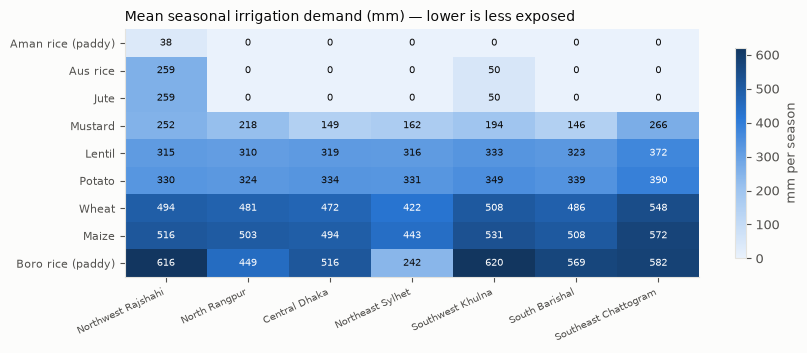

In [5]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
order = summary.groupby("crop")["irrigation_mm"].mean().sort_values().index
data = pivot.loc[order]
im = ax.imshow(data.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(len(data.columns)))
ax.set_xticklabels([pretty(c) for c in data.columns], rotation=25, ha="right", fontsize=7)
ax.set_yticks(range(len(data.index))); ax.set_yticklabels(data.index, fontsize=8)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanpercentile(data.values, 65) else INK)
ax.set_title("Mean seasonal irrigation demand (mm) — lower is less exposed", loc="left")
fig.colorbar(im, ax=ax, shrink=0.85, label="mm per season")
fig.tight_layout(); plt.show()

**Two things in that chart are correct but look like faults, so read them carefully:**

- **Zeroes are real.** Aman rice grows through the monsoon; in six of seven regions
  effective rainfall exceeds the crop's demand across the season, so a rainfed crop needs
  no supplementary irrigation. Only Rajshahi, the driest region, shows a small deficit.
- **Aus rice and Jute are identical rows** because this demonstration gives them the same
  season window and the same Kc (1.10). With one mid-season coefficient there is nothing
  to tell them apart. A real catalogue supplies stage-specific Kc curves and distinct
  windows, and the rows diverge.

Boro rice is the opposite case: a winter crop grown in the dry season, needing 450–620 mm
of irrigation in every region. That single number is the most decision-relevant output in
this notebook.

## 4. How farmer and field inputs change the ranking

The ranking above is purely climatic. Three inputs move it, and they are exactly the
ones the FieldShift plan says must come from the farmer and the reviewed catalogue:

| Input | Where it enters | Effect |
|---|---|---|
| Soil texture | curve number `CN` in effective rainfall (70 here) | sandy soils raise CN, so more rain becomes runoff and irrigation demand rises |
| Irrigation availability | feasibility filter, not the water balance | a crop needing 400 mm may be infeasible on rainfed land even if climatically ideal |
| Crop stage / Kc timing | replace single `Kc mid` with the FAO-56 Kc curve | early-season demand is ~40% of mid-season, so single-Kc overstates short-duration crops |

Demonstrating the soil sensitivity:

In [6]:
for cn in (55, 70, 85):
    s = 25400 / cn - 254
    rain = balance.groupby("crop")["rain_mm"].mean()
    pe = np.where(rain > 0.2 * s, (rain - 0.2 * s) ** 2 / (rain + 0.8 * s), 0)
    etc = balance.groupby("crop")["etc_mm"].mean()
    demand = (etc - pe).clip(lower=0)
    print(f"CN {cn}: mean irrigation demand across crops = {demand.mean():.0f} mm/season")

CN 55: mean irrigation demand across crops = 282 mm/season
CN 70: mean irrigation demand across crops = 268 mm/season
CN 85: mean irrigation demand across crops = 249 mm/season


## 5. What this notebook does and does not establish

**Establishes:** with real 2022–2026 weather, the irrigation demand of each candidate
crop per region, its heat exposure, and a defensible ordering of options.

**Does not establish:** yield, profit, or agronomic suitability. The FieldShift plan is
explicit that a rotation comparison must show *why* an option was rejected — and that
when the evidence cannot support two alternatives, the app should say so rather than
invent them.

**Two caveats worth keeping in the UI:**

1. **Paddy is not comparable to upland crops on irrigation demand alone.** Flooded rice
   also receives bund seepage and rainfall ponding, which a simple bucket ignores; the
   AgriFusion engine models this separately as a field-water term.
2. **The weather is historical, not a forecast.** The honest framing is "in the last
   four seasons this crop would have needed X mm", never "this crop will need X mm".